In [27]:
import matplotlib.pyplot as plt
import numpy as np
import scipy

# Part I - FMCW Radar principle

**Frequency-Modulated Continuous Wave (FMCW) radar** measures the range (and, from the Doppler shift, the velocity) of a target by continuously transmitting a signal whose frequency changes linearly with time — a **chirp** — rather than transmitting short pulses. It is the operating principle behind the surface-based scatterometers used during CEMSIE.

Instead of timing how long a short pulse takes to return (as in pulsed radar), an FMCW radar converts the round-trip travel time into a **frequency difference** between the transmitted and received chirps, which can be measured very precisely with an Fourier transform.

This notebook builds an FMCW radar simulation from scratch, in five steps:

1. Generate the transmitted chirp.
2. Simulate the received echo — a delayed, weaker copy of the chirp reflected from a target at a known range.
3. **Mix** (multiply) the transmitted and received signals to obtain a low-frequency "beat" signal.
4. Take the Fourier transform of the beat signal to find the beat frequency.
5. Convert the beat frequency back into target range.

## System block diagram

A basic FMCW radar consists of the following functional blocks:

- **RF generator:** Produces the continuous-wave signal whose frequency is swept ("chirp") linearly over time.
- **Power divider:** Splits the generator's output into two paths: one goes to the transmitting antenna, and a second is send as reference to the mixer.
- **Transmitting antenna:** radiates the signal towards the target.
- **Target:** reflects a delayed, attenuated copy of the chirp back to the radar. The round-trip delay is $\tau = 2R/c$, where $R$ is the target range and $c$ the speed of light.
- **Receiving antenna:** Captures the backscattered sigal from the target.
- **Pre-amplifier:** Low-noise amplifier (LNA) that boosts the weak received signal before firther processing.
- **Mixer:** The heart of FMCW ranging. It multiplies the amplified received signal with the reference chirp captured from the power divider. This produces sum and difference frequency components; the difference frequency (the "beat frequency") is directly proportional to the round-trip delay and hence the target's range.
- **Low-pass filter:** Removes the high-frequency sum component to keep only the low-frequency beat signal.
- **Aamplifier:** Boosts the signal before digitization.
- **ADC:** Analog to digital converter.

The figure below draws this signal chain. Image source: https://en.wikipedia.org/wiki/Continuous-wave_radar

<img src="images/FMCW_block_diagram.png" alt="FMCW radar block diagram" width="600">

## The transmit chirp

The transmit chirp is a linear frequency ramp between $f_0$ and $f_1$ of duration $T$. The bandwith is $B = f_0 - f_1$.

Theerefore, the **chirp slope** is $$S = \frac{B}{T} = \frac{f_1 - f_0}{T}$$

<img src="images/transmit_chirp_f_v_t.png" alt="Transmit chirp" width="600">

**Task 1a :** with the help of the `scipy.signal` documentation, generate a linear chirp using the paraeters defined below. 

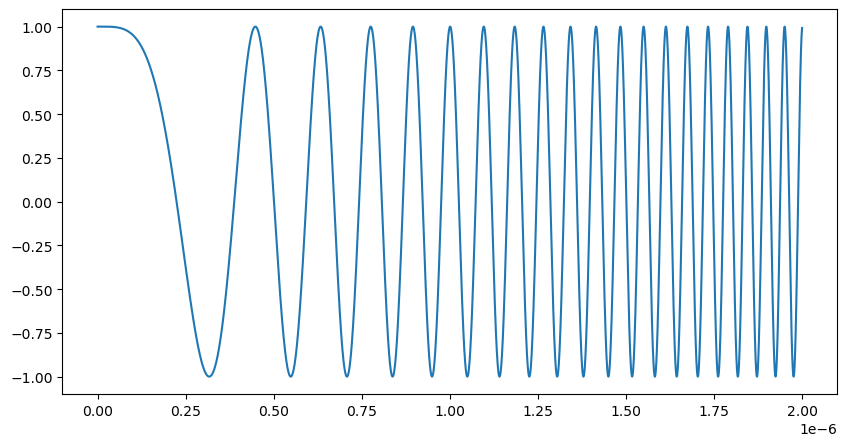

In [28]:
T = 2e-3  # chirp length (s)
f0 = 30e9 # lower frequency (Hz)
f1 = 10e9 # upper frequency (Hz)

n_samples = int(5e6) # dimensionless
sampling_rate = n_samples / T
t_axis = np.linspace(0, T, n_samples)

############## TO COMPLETE: ##############

transmit_chirp = scipy.signal.chirp(t_axis, f0=f0, f1=f1, t1=T, method='linear')

##########################################


fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = int(5e3)
ax.plot(t_axis[:n_samples_plot], transmit_chirp[:n_samples_plot])

## The receive chirp

The receive chirp is a delayed and attenuated version of the transmit chirp.

The delay between the tramsmitted and received chirps is $\tau = \frac{2R}{c}$
where:
- $R$ is the range of the target,
- $c$ is the speed of light

The **beat frequency** $\Delta f$ is the difference between the transmit and receive frequencies: $$\Delta f = f_{Tx}(t) - f_{Rx}(t)$$.

<img src="images/receive_chirp_f_v_t.png" alt="Transmit chirp" width="600">

Since the frequency ramp is linear, the beat frequency is constant and can be written: $$\Delta f = S\,\tau = \frac{f_1-f_0}{T}\cdot\frac{2R}{c}$$

Therefore, $\Delta f $ varies linearly with the target range $R$.

**Task 1b :** complete the expression of the delay $\tau$.

In [29]:
c = 3e8          # speed of light (m/s)
target_range = 2 # simulated target range (m). We will try to retreive this number - normally unknown - with some signal processing.

############## TO COMPLETE: ##############

tau = 2 * target_range / c

##########################################

## Simulating the received echo and mixing

To simulate the receiver, the transmitted chirp is time-shifted by `time_delay` ($\tau = 2R/c$) to create `receive_chirp` — this stands in for the echo reflected from the target. (A real echo would also be attenuated and noisy, but for this exercise we only care about its frequency content.)

The two signals are then **mixed** — multiplied sample-by-sample — to produce `mixed`. Multiplying two sinusoids of frequencies $f_{TX}(t)$ and $f_{RX}(t)$ produces components at the *sum* $f_{TX}(t)+f_{RX}(t)$ (fast) and the *difference* $f_{TX}(t)-f_{RX}(t) = \Delta f$ (slow, and constant during the overlap of the two chirps). The plot below shows the mixed signal in the time domain: the fast oscillation is the sum-frequency term, while the much slower envelope corresponds to $\Delta f$ — the beat frequency we'll extract next.

**Task 1c :** complete the expression of the mixed signal.

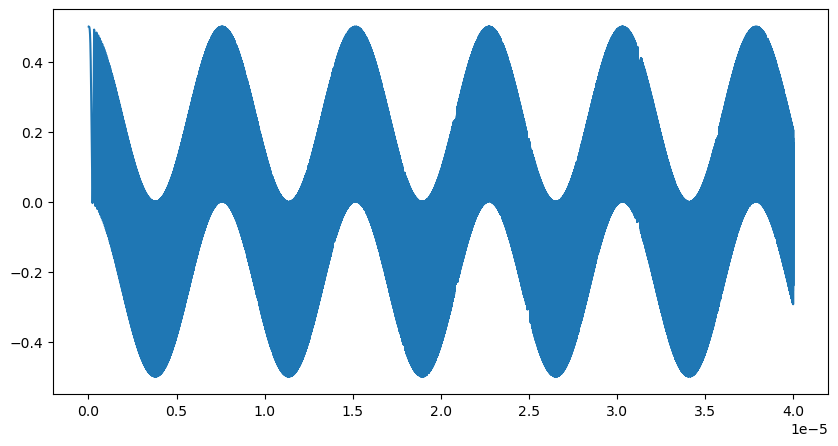

In [30]:
samples_until_return = int(sampling_rate * tau) # n samples before the return signal starts being received
t_axis = np.linspace(0, T + tau , n_samples + samples_until_return)
nan_pad = np.full(samples_until_return, np.nan) # pad with NaN values
Gr = 0.5 # gain of the return signal (dimensionless)
receive_chirp = np.append(nan_pad, Gr * transmit_chirp, axis=0)
transmit_chirp = np.append(transmit_chirp, nan_pad, axis=0)

############## TO COMPLETE: ##############

mixed = receive_chirp * transmit_chirp

##########################################

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = int(1e5)
ax.plot(t_axis[:n_samples_plot], mixed[:n_samples_plot])

## Extracting the beat frequency with a Fourier transform

A real receiver would low-pass filter `mixed` to remove the sum-frequency term before digitizing it; here we instead go straight to the FFT of the overlapping region of `mixed` (the portion where both the transmitted and received chirps are present). Because the beat frequency $\Delta f$ is constant over that whole interval, it appears as a single, sharp, dominant peak in the power spectrum — visible below on a log scale.

**Task 1d :** With the help of the `scipy.fft` documentation, complete the expression of the mixed signal FFT, power and frequency axis.

Text(0, 0.5, 'Power Density')

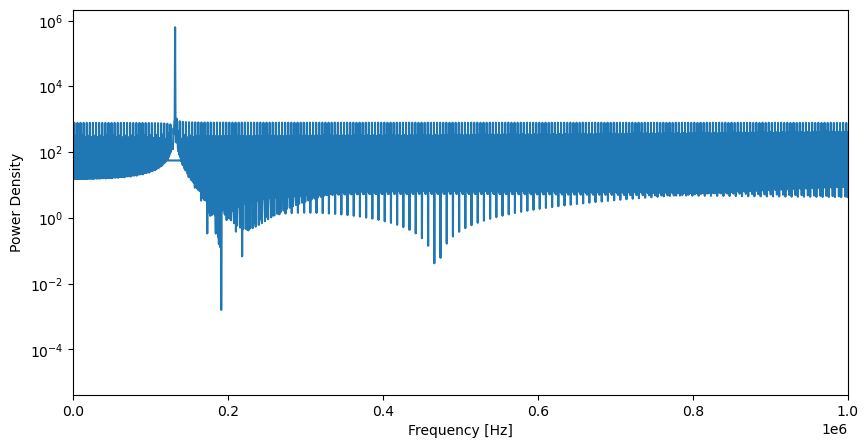

In [31]:
############## TO COMPLETE: ##############

fft = scipy.fft.fft(mixed[samples_until_return: -samples_until_return])
fft_power = abs(fft)
xf = scipy.fft.fftfreq(n_samples - samples_until_return, T / (n_samples - samples_until_return))

##########################################

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(xf, fft_power)
ax.set_xlim(0, 1e6)
ax.set_yscale('log')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Power Density')

**Task 1e :** Extract the beat frequency $\Delta f$ from the spectrum.

In [32]:
############## TO COMPLETE: ##############

f_beat = xf[np.argmax(fft_power)]

##########################################

## From beat frequency to range

Recall :

$$\Delta f = S\,\tau = \frac{f_1-f_0}{T}\cdot\frac{2R}{c}$$

Therefore:

$$R = \frac{c\,\Delta f\,T}{2(f_1-f_0)}$$

**Task 1f :** calculate the range of the target.

In [33]:
############## TO COMPLETE: ##############

radar_range = np.abs(c * f_beat * T / (2 * (f1 - f0)))

##########################################

print(f'Radar range: {radar_range} m')

Radar range: 1.98 m


# Part II - FMCW radar with multiple targets

In this part, we extend the simulation to a scene with **several targets at different ranges**, instead of just one.

The transmitted chirp reflects off every target, so the received signal is the superposition of several delayed and attenuated copies of the transmit chirp — one per target. Since mixing (multiplication with the reference chirp) distributes over addition, the mixed signal is simply the **sum of the single-target beat signals** from Part I, each oscillating at its own beat frequency $\Delta f_i = S\,\tau_i$.

The power spectrum of the mixed signal should therefore show **one peak per target**, at a frequency proportional to its range.

## The transmit chirp

We regenerate the same transmit chirp as in Part I.

In [ ]:
T = 2e-3  # chirp length (s)
f0 = 30e9 # lower frequency (Hz)
f1 = 10e9 # upper frequency (Hz)

n_samples = int(5e6) # dimensionless
sampling_rate = n_samples / T
t_axis = np.linspace(0, T, n_samples)

############## TO COMPLETE: ##############

transmit_chirp = scipy.signal.chirp(t_axis, f0=f0, f1=f1, t1=T, method='linear')

##########################################

## Multiple targets

We now place three targets at ranges 1, 2 and 3 m, and compute the round-trip delay $\tau_i = 2R_i/c$ of each one.

In [ ]:
c = 3e8                     # speed of light (m/s)
target_ranges = [1, 2, 3]   # simulated target ranges (m)
Gr = 0.5                     # gain of the return signal, same for every target (dimensionless)

############## TO COMPLETE: ##############

taus = [2 * R / c for R in target_ranges]  # round-trip delay of each target (s)

##########################################

## Simulating the received echoes and mixing

Each target contributes a copy of the transmit chirp, delayed by its own $\tau_i$ and attenuated by `Gr`. Unlike in Part I, we cannot pad the missing samples with `NaN`, since summing several echoes together would turn every sample touched by a `NaN` into `NaN`. Instead, each echo is zero-padded so all echoes share the same length and can simply be summed to build the total received signal `receive_chirp`.

The transmit chirp is zero-padded the same way so that `transmit_chirp` and `receive_chirp` have matching lengths, then mixed (multiplied) as in Part I.

Text(0, 0.5, 'Amplitude')

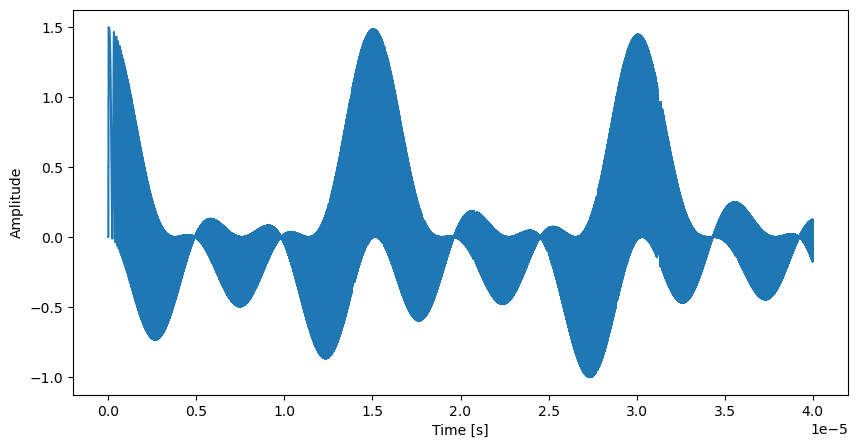

In [ ]:
delay_samples = [int(sampling_rate * tau) for tau in taus] # n samples before each return signal starts being received
max_delay_samples = max(delay_samples)

t_axis = np.linspace(0, T + max(taus), n_samples + max_delay_samples)

# sum of the delayed, attenuated, zero-padded echoes from every target
receive_chirp = np.zeros(n_samples + max_delay_samples)
for d in delay_samples:
    receive_chirp += np.pad(Gr * transmit_chirp, (d, max_delay_samples - d))

transmit_chirp = np.pad(transmit_chirp, (0, max_delay_samples))

############## TO COMPLETE: ##############

mixed = receive_chirp * transmit_chirp

##########################################

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
n_samples_plot = int(1e5)
ax.plot(t_axis[:n_samples_plot], mixed[:n_samples_plot])
ax.set_xlabel('Time [s]')
ax.set_ylabel('Amplitude')

## Extracting the beat frequencies with a Fourier transform

The beat frequency of each target is constant only once *every* target has started returning and while the transmit chirp is still being emitted, i.e. for $t \in [\tau_{max}, T]$. We therefore take the FFT of `mixed` restricted to that common overlap region, exactly as in Part I but using the delay of the *farthest* target, `max_delay_samples`.

Because the mixed signal is now the sum of three beat signals, its power spectrum shows three separate peaks, one per target.

Text(0, 0.5, 'Power Density')

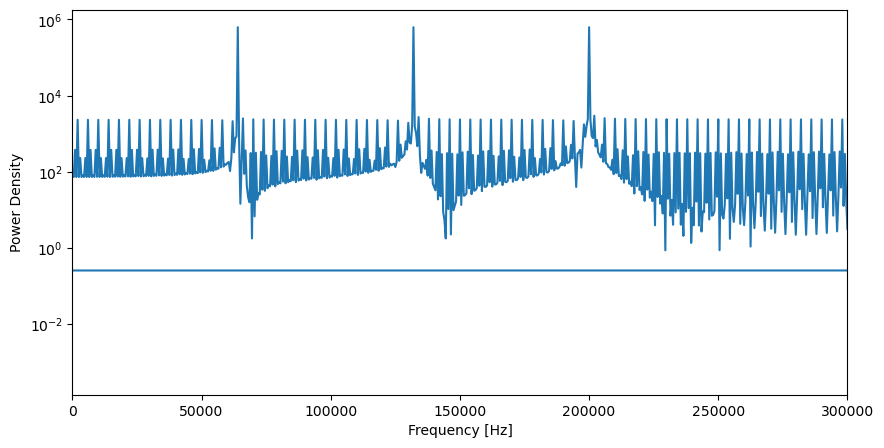

In [ ]:
overlap = mixed[max_delay_samples : -max_delay_samples]
n_valid = len(overlap)

############## TO COMPLETE: ##############

fft = scipy.fft.fft(overlap)
fft_power = abs(fft)
xf = scipy.fft.fftfreq(n_valid, T / n_valid)

##########################################


fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(xf, fft_power)
ax.set_xlim(0, 3e5)
ax.set_yscale('log')
ax.set_xlabel('Frequency [Hz]')
ax.set_ylabel('Power Density')

## From beat frequencies to ranges

Each peak in the spectrum above corresponds to one target. We find them with `scipy.signal.find_peaks` (keeping only peaks above half the maximum, to reject FFT side-lobes), then convert every beat frequency to a range using the same relation as in Part I:

$$R = \frac{c\,\Delta f\,T}{2(f_1-f_0)}$$

In [ ]:
positive = xf > 0
xf_pos = xf[positive]
fft_power_pos = fft_power[positive]

peak_idx, _ = scipy.signal.find_peaks(fft_power_pos, height=0.5 * fft_power_pos.max())
f_beats = xf_pos[peak_idx]

############## TO COMPLETE: ##############

radar_ranges = np.sort(np.abs(c * f_beats * T / (2 * (f1 - f0))))

##########################################

for r in radar_ranges:
    print(f'Detected target range: {r:.2f} m')

Detected target range: 0.96 m
Detected target range: 1.98 m
Detected target range: 3.00 m


# Part III - Continuous target

# Part IV - CEMSIE data analysis